# Phase 5 - Feature Selection and Feature Analysis

This notebook investigates whether the 31-feature input space can be reduced while maintaining comparable standard phishing-classification performance. Feature ranking and selection are fitted using training data only. The Phase 3 split and Phase 4 baseline results are not overwritten.

Feature selection is evaluated for standard phishing-classification performance. Unseen-domain evaluation remains a limitation because the current benchmark does not contain domain identifiers.

## Load Reproducible Train/Test Data

In [1]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / 'dataset' / 'processed'
RESULTS_DIR = PROJECT_ROOT / 'results'
MODELS_DIR = PROJECT_ROOT / 'models'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

X_train = pd.read_csv(PROCESSED_DIR / 'X_train_tree.csv')
X_test = pd.read_csv(PROCESSED_DIR / 'X_test_tree.csv')
y_train = pd.read_csv(PROCESSED_DIR / 'y_train.csv')['class']
y_test = pd.read_csv(PROCESSED_DIR / 'y_test.csv')['class']
X_test_original = X_test.copy(deep=True)
FEATURE_COUNTS = [5, 10, 15, 20, 25]
ALL_FEATURE_COUNT = X_train.shape[1]
FEATURE_COLUMNS = list(X_train.columns)
PHISHING_LABEL = -1
LEGITIMATE_LABEL = 1
LABEL_NAMES = {PHISHING_LABEL: 'Phishing', LEGITIMATE_LABEL: 'Legitimate'}

print('Loaded exact Phase 3 train/test artifacts.')
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

Loaded exact Phase 3 train/test artifacts.
X_train: (7737, 31)
X_test: (3317, 31)
y_train: (7737,)
y_test: (3317,)


## Verify Dataset and Labels

In [2]:
assert X_train.shape == (7737, 31)
assert X_test.shape == (3317, 31)
assert y_train.shape == (7737,)
assert y_test.shape == (3317,)
assert FEATURE_COLUMNS == list(X_test.columns)
assert set(pd.concat([y_train, y_test]).unique()) == {PHISHING_LABEL, LEGITIMATE_LABEL}
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0
print('Verified labels: -1 = Phishing; 1 = Legitimate')
print('Training distribution:')
display(y_train.value_counts().sort_index().rename('count').to_frame())
print('Testing distribution:')
display(y_test.value_counts().sort_index().rename('count').to_frame())
print('The unchanged test set will be used for every comparison.')

Verified labels: -1 = Phishing; 1 = Legitimate
Training distribution:


,count
class,
-1,3428
1,4309


Testing distribution:


,count
class,
-1,1469
1,1848


The unchanged test set will be used for every comparison.


## Random Forest Feature Importance

,feature,importance,rank
0,HTTPS,0.308997,1
1,AnchorURL,0.234452,2
2,WebsiteTraffic,0.072376,3
3,Index,0.070366,4
4,SubDomains,0.059150,5
5,PrefixSuffix-,0.040347,6
6,LinksInScriptTags,0.036190,7
7,ServerFormHandler,0.018096,8
8,RequestURL,0.017977,9
9,LinksPointingToPage,0.016651,10


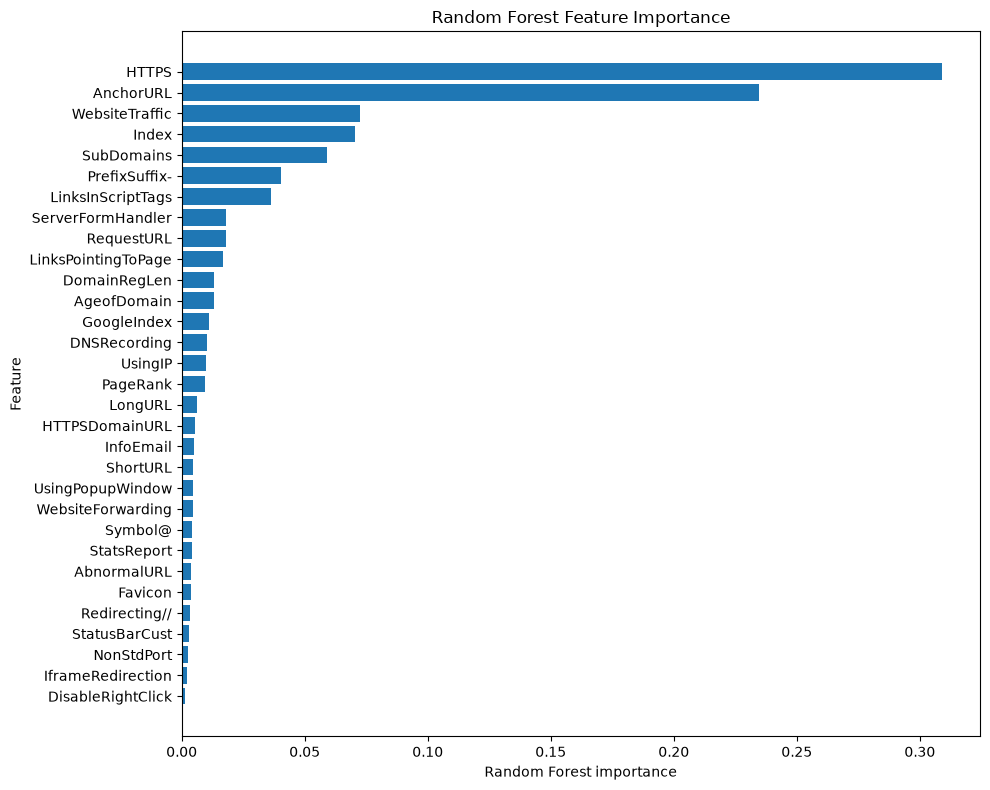

Importance was fitted using X_train only.


In [3]:
importance_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
importance_model.fit(X_train, y_train)
feature_importance = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'importance': importance_model.feature_importances_,
}).sort_values('importance', ascending=False).reset_index(drop=True)
feature_importance['rank'] = np.arange(1, len(feature_importance) + 1)
feature_importance.to_csv(RESULTS_DIR / 'feature_importance.csv', index=False)
display(feature_importance)

plt.figure(figsize=(10, 8))
importance_plot = feature_importance.sort_values('importance')
plt.barh(importance_plot['feature'], importance_plot['importance'])
plt.xlabel('Random Forest importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'feature_importance.png', dpi=150)
plt.show()
plt.close()

ranked_features = feature_importance['feature'].tolist()
top_k_feature_sets = {
    f'Top {k}': ranked_features[:k] for k in FEATURE_COUNTS
}
top_k_feature_sets[f'All {ALL_FEATURE_COUNT}'] = ranked_features
print('Importance was fitted using X_train only.')

## Top-K Feature Selection

In [4]:
print('Feature subsets created from training-only Random Forest ranking:')
for k in FEATURE_COUNTS:
    print(f'Top {k}: {k} features')
print(f'All {ALL_FEATURE_COUNT}: {ALL_FEATURE_COUNT} features')

assert FEATURE_COUNTS == [5, 10, 15, 20, 25]
assert len(top_k_feature_sets) == 6
assert all(len(features) in FEATURE_COUNTS + [ALL_FEATURE_COUNT] for features in top_k_feature_sets.values())
assert set(top_k_feature_sets['Top 5']).issubset(set(top_k_feature_sets['Top 10']))
assert set(top_k_feature_sets[f'All {ALL_FEATURE_COUNT}']) == set(FEATURE_COLUMNS)

Feature subsets created from training-only Random Forest ranking:
Top 5: 5 features
Top 10: 10 features
Top 15: 15 features
Top 20: 20 features
Top 25: 25 features
All 31: 31 features


## Random Forest Evaluation

In [5]:
def evaluate_predictions(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    if hasattr(model, 'predict_proba'):
        classes = list(model.classes_)
        scores = model.predict_proba(X_eval)[:, classes.index(PHISHING_LABEL)]
    else:
        decision = np.asarray(model.decision_function(X_eval))
        classes = list(model.classes_)
        scores = decision if classes[1] == PHISHING_LABEL else -decision
    matrix = confusion_matrix(y_eval, predictions, labels=[LEGITIMATE_LABEL, PHISHING_LABEL])
    tn, fp, fn, tp = matrix.ravel()
    binary_target = (y_eval == PHISHING_LABEL).astype(int)
    return {
        'Accuracy': accuracy_score(y_eval, predictions),
        'Precision': precision_score(y_eval, predictions, pos_label=PHISHING_LABEL, zero_division=0),
        'Recall': recall_score(y_eval, predictions, pos_label=PHISHING_LABEL, zero_division=0),
        'F1': f1_score(y_eval, predictions, pos_label=PHISHING_LABEL, zero_division=0),
        'Specificity': tn / (tn + fp) if tn + fp else 0.0,
        'ROC_AUC': roc_auc_score(binary_target, scores),
        'FPR': fp / (fp + tn) if fp + tn else 0.0,
        'FNR': fn / (fn + tp) if fn + tp else 0.0,
        'confusion_matrix': matrix,
        'predictions': predictions,
        'scores': scores,
    }

def fit_random_forest(features):
    model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    model.fit(X_train[features], y_train)
    evaluation = evaluate_predictions(model, X_test[features], y_test)
    return model, evaluation

rf_records = []
rf_models = {}
for subset_name, features in top_k_feature_sets.items():
    model, evaluation = fit_random_forest(features)
    rf_models[subset_name] = model
    rf_records.append({
        'Feature_Count': len(features),
        'Features': '|'.join(features),
        **{metric: evaluation[metric] for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'Specificity', 'ROC_AUC', 'FPR', 'FNR']},
    })
rf_results = pd.DataFrame(rf_records).sort_values('Feature_Count').reset_index(drop=True)
rf_results.to_csv(RESULTS_DIR / 'feature_selection_random_forest.csv', index=False)
display(rf_results)
assert X_test.equals(X_test_original), 'The test set was modified.'

,Feature_Count,Features,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC,FPR,FNR
0,5,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomains,0.917395,0.905085,0.908781,0.906929,0.924242,0.973025,0.075758,0.091219
1,10,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,0.949050,0.943989,0.940776,0.942380,0.955628,0.990099,0.044372,0.059224
2,15,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,0.960506,0.958219,0.952349,0.955275,0.966991,0.994018,0.033009,0.047651
3,20,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,0.970154,0.969178,0.963240,0.966200,0.975649,0.995833,0.024351,0.036760
4,25,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,0.971058,0.971174,0.963240,0.967191,0.977273,0.995958,0.022727,0.036760
5,31,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,0.971963,0.972527,0.963921,0.968205,0.978355,0.996027,0.021645,0.036079


## SelectKBest Feature Selection

In [6]:
selectkbest_feature_sets = {}
selectkbest_selectors = {}
for k in FEATURE_COUNTS:
    selector = SelectKBest(score_func=f_classif, k=k)
    selector.fit(X_train, y_train)
    selected = list(X_train.columns[selector.get_support()])
    selectkbest_selectors[k] = selector
    selectkbest_feature_sets[k] = selected
    assert len(selected) == k
print('SelectKBest selectors were fitted using X_train only.')
for k, features in selectkbest_feature_sets.items():
    print(f'k={k}: {features}')

SelectKBest selectors were fitted using X_train only.
k=5: ['PrefixSuffix-', 'SubDomains', 'HTTPS', 'AnchorURL', 'WebsiteTraffic']
k=10: ['PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'RequestURL', 'AnchorURL', 'LinksInScriptTags', 'ServerFormHandler', 'AgeofDomain', 'WebsiteTraffic']
k=15: ['UsingIP', 'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'RequestURL', 'AnchorURL', 'LinksInScriptTags', 'ServerFormHandler', 'AgeofDomain', 'DNSRecording', 'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'StatsReport']
k=20: ['UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'NonStdPort', 'RequestURL', 'AnchorURL', 'LinksInScriptTags', 'ServerFormHandler', 'AbnormalURL', 'AgeofDomain', 'DNSRecording', 'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'StatsReport']
k=25: ['UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//', 'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'A

## SelectKBest Random Forest Evaluation

In [7]:
selectkbest_rf_records = []
selectkbest_rf_models = {}
for k, features in selectkbest_feature_sets.items():
    model, evaluation = fit_random_forest(features)
    selectkbest_rf_models[k] = model
    selectkbest_rf_records.append({
        'Feature_Count': k,
        'Features': '|'.join(features),
        **{metric: evaluation[metric] for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'Specificity', 'ROC_AUC', 'FPR', 'FNR']},
    })
selectkbest_rf_results = pd.DataFrame(selectkbest_rf_records).sort_values('Feature_Count').reset_index(drop=True)
selectkbest_rf_results.to_csv(RESULTS_DIR / 'selectkbest_random_forest.csv', index=False)
display(selectkbest_rf_results)
assert X_test.equals(X_test_original), 'The test set was modified.'

,Feature_Count,Features,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC,FPR,FNR
0,5,PrefixSuffix-|SubDomains|HTTPS|AnchorURL|Websi...,0.937293,0.915623,0.945541,0.930342,0.930736,0.983846,0.069264,0.054459
1,10,PrefixSuffix-|SubDomains|HTTPS|DomainRegLen|Re...,0.953874,0.953793,0.941457,0.947585,0.963745,0.990112,0.036255,0.058543
2,15,UsingIP|PrefixSuffix-|SubDomains|HTTPS|DomainR...,0.963220,0.963524,0.953029,0.958248,0.971320,0.993813,0.028680,0.046971
3,20,UsingIP|LongURL|ShortURL|Symbol@|PrefixSuffix-...,0.968646,0.970365,0.958475,0.964384,0.976732,0.993998,0.023268,0.041525
4,25,UsingIP|LongURL|ShortURL|Symbol@|Redirecting//...,0.972867,0.977824,0.960517,0.969093,0.982684,0.995605,0.017316,0.039483


## SVM with Feature Selection

In [ ]:
svm_records = []
svm_models = {}
svm_feature_sets = {}
for k in FEATURE_COUNTS:
    selected_features = selectkbest_feature_sets[k]
    pipeline = Pipeline([
        ('select_k_best', SelectKBest(score_func=f_classif, k=k)),
        ('standard_scaler', StandardScaler()),
        ('svm', SVC(kernel='rbf', C=1.0, random_state=42)),
    ])
    pipeline.fit(X_train, y_train)
    evaluation = evaluate_predictions(pipeline, X_test, y_test)
    svm_models[k] = pipeline
    svm_feature_sets[k] = selected_features
    svm_records.append({
        'Feature_Count': k,
        'Features': '|'.join(selected_features),
        **{metric: evaluation[metric] for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'Specificity', 'ROC_AUC', 'FPR', 'FNR']},
    })
    
svm_results = pd.DataFrame(svm_records).sort_values('Feature_Count').reset_index(drop=True)
svm_results.to_csv(RESULTS_DIR / 'selectkbest_svm.csv', index=False)
display(svm_results)
print('Each SVM selector and scaler was fitted only on X_train inside the Pipeline.')
assert X_test.equals(X_test_original), 'The test set was modified.'

,Feature_Count,Features,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC,FPR,FNR
0,5,PrefixSuffix-|SubDomains|HTTPS|AnchorURL|Websi...,0.935182,0.907143,0.950987,0.928548,0.922619,0.970678,0.077381,0.049013
1,10,PrefixSuffix-|SubDomains|HTTPS|DomainRegLen|Re...,0.952668,0.954294,0.938053,0.946104,0.964286,0.988481,0.035714,0.061947
2,15,UsingIP|PrefixSuffix-|SubDomains|HTTPS|DomainR...,0.950558,0.955975,0.931246,0.943448,0.965909,0.990054,0.034091,0.068754
3,20,UsingIP|LongURL|ShortURL|Symbol@|PrefixSuffix-...,0.951161,0.957954,0.930565,0.944061,0.967532,0.989009,0.032468,0.069435
4,25,UsingIP|LongURL|ShortURL|Symbol@|Redirecting//...,0.960205,0.968465,0.940776,0.954420,0.975649,0.990437,0.024351,0.059224


Each SVM selector and scaler was fitted only on X_train inside the Pipeline.


## Model/Feature Comparison

In [9]:
comparison_records = []
for _, row in rf_results.iterrows():
    method = 'Random Forest All Features' if row['Feature_Count'] == ALL_FEATURE_COUNT else 'Random Forest Top-K'
    comparison_records.append({'Method': method, 'Model': 'Random Forest', **row.to_dict()})
for _, row in selectkbest_rf_results.iterrows():
    comparison_records.append({'Method': 'SelectKBest', 'Model': 'Random Forest', **row.to_dict()})
for _, row in svm_results.iterrows():
    comparison_records.append({'Method': 'SelectKBest + StandardScaler', 'Model': 'SVM', **row.to_dict()})
comparison = pd.DataFrame(comparison_records)
comparison = comparison[['Method', 'Feature_Count', 'Features', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'Specificity', 'ROC_AUC', 'FPR', 'FNR']]
comparison = comparison.sort_values(['F1', 'ROC_AUC'], ascending=False).reset_index(drop=True)
display(comparison)
assert len(comparison) == 16
assert X_test.equals(X_test_original), 'The test set was modified.'

,Method,Feature_Count,Features,Model,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC,FPR,FNR
0,SelectKBest,25,UsingIP|LongURL|ShortURL|Symbol@|Redirecting//...,Random Forest,0.972867,0.977824,0.960517,0.969093,0.982684,0.995605,0.017316,0.039483
1,Random Forest All Features,31,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,Random Forest,0.971963,0.972527,0.963921,0.968205,0.978355,0.996027,0.021645,0.036079
2,Random Forest Top-K,25,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,Random Forest,0.971058,0.971174,0.963240,0.967191,0.977273,0.995958,0.022727,0.036760
3,Random Forest Top-K,20,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,Random Forest,0.970154,0.969178,0.963240,0.966200,0.975649,0.995833,0.024351,0.036760
4,SelectKBest,20,UsingIP|LongURL|ShortURL|Symbol@|PrefixSuffix-...,Random Forest,0.968646,0.970365,0.958475,0.964384,0.976732,0.993998,0.023268,0.041525
5,SelectKBest,15,UsingIP|PrefixSuffix-|SubDomains|HTTPS|DomainR...,Random Forest,0.963220,0.963524,0.953029,0.958248,0.971320,0.993813,0.028680,0.046971
6,Random Forest Top-K,15,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,Random Forest,0.960506,0.958219,0.952349,0.955275,0.966991,0.994018,0.033009,0.047651
7,SelectKBest + StandardScaler,25,UsingIP|LongURL|ShortURL|Symbol@|Redirecting//...,SVM,0.960205,0.968465,0.940776,0.954420,0.975649,0.990437,0.024351,0.059224
8,SelectKBest,10,PrefixSuffix-|SubDomains|HTTPS|DomainRegLen|Re...,Random Forest,0.953874,0.953793,0.941457,0.947585,0.963745,0.990112,0.036255,0.058543
9,SelectKBest + StandardScaler,10,PrefixSuffix-|SubDomains|HTTPS|DomainRegLen|Re...,SVM,0.952668,0.954294,0.938053,0.946104,0.964286,0.988481,0.035714,0.061947


## Feature Selection Visualizations

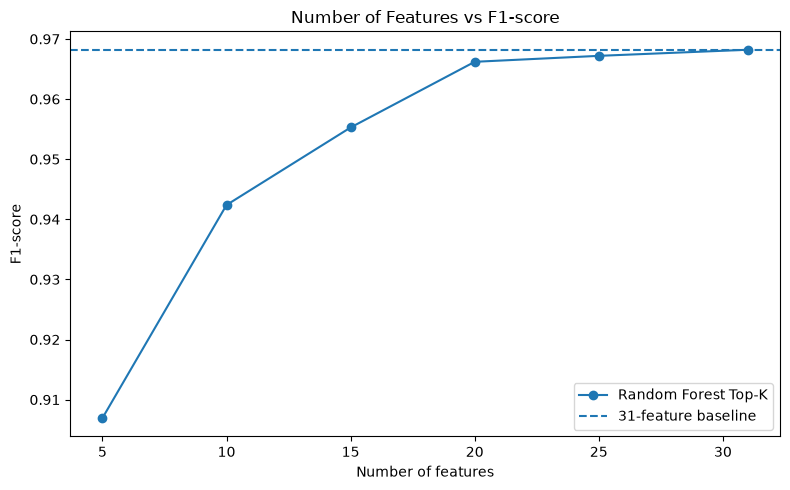

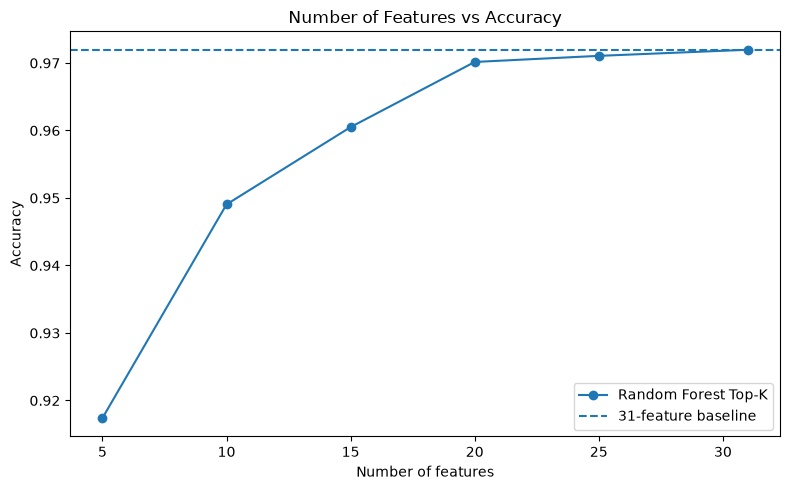

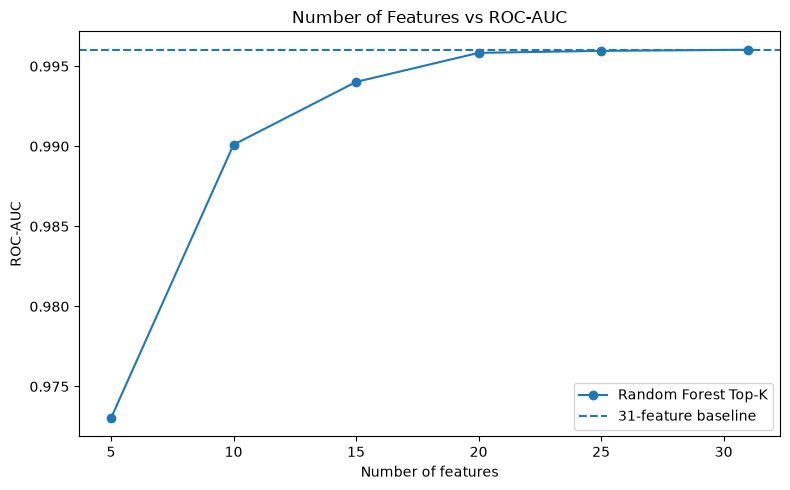

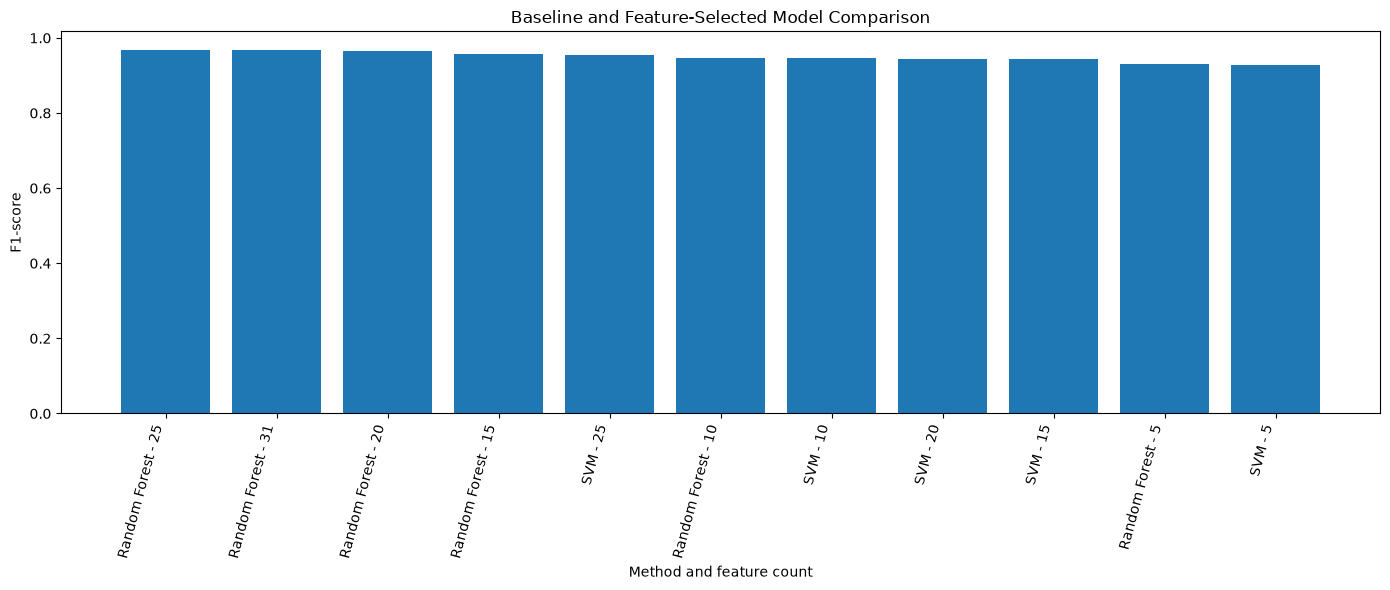

In [10]:
# Curves compare the Random Forest Top-K path with its all-feature baseline.
rf_plot = rf_results.copy()
baseline_row = rf_plot[rf_plot['Feature_Count'] == ALL_FEATURE_COUNT].iloc[0]

for metric, filename, ylabel in [
    ('F1', 'features_vs_f1.png', 'F1-score'),
    ('Accuracy', 'features_vs_accuracy.png', 'Accuracy'),
    ('ROC_AUC', 'features_vs_roc_auc.png', 'ROC-AUC'),
]:
    plt.figure(figsize=(8, 5))
    plt.plot(rf_plot['Feature_Count'], rf_plot[metric], marker='o', label='Random Forest Top-K')
    plt.axhline(baseline_row[metric], linestyle='--', label='31-feature baseline')
    plt.xlabel('Number of features')
    plt.ylabel(ylabel)
    plt.title(f'Number of Features vs {ylabel}')
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / filename, dpi=150)
    plt.show()
    plt.close()

comparison_plot = comparison.copy()
comparison_plot['Label'] = comparison_plot['Model'] + ' - ' + comparison_plot['Feature_Count'].astype(str)
plt.figure(figsize=(14, 6))
plt.bar(comparison_plot['Label'], comparison_plot['F1'])
plt.xlabel('Method and feature count')
plt.ylabel('F1-score')
plt.title('Baseline and Feature-Selected Model Comparison')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'feature_selection_model_comparison.png', dpi=150)
plt.show()
plt.close()

## Final Feature Set

In [11]:
baseline_metrics = comparison[(comparison['Model'] == 'Random Forest') & (comparison['Feature_Count'] == ALL_FEATURE_COUNT)].iloc[0]
reduced_candidates = comparison[comparison['Feature_Count'] < ALL_FEATURE_COUNT].copy()
comparable = reduced_candidates[
    (reduced_candidates['F1'] >= baseline_metrics['F1'] - 0.01)
    & (reduced_candidates['ROC_AUC'] >= baseline_metrics['ROC_AUC'] - 0.01)
    & (reduced_candidates['Recall'] >= baseline_metrics['Recall'] - 0.01)
]
if len(comparable):
    selected_row = comparable.sort_values(
        ['Feature_Count', 'F1', 'ROC_AUC', 'Recall', 'Specificity'],
        ascending=[True, False, False, False, False],
    ).iloc[0]
    selection_reason = 'Smallest reduced feature set within 0.01 of the all-feature baseline for F1, ROC-AUC, and phishing recall.'
else:
    selected_row = comparison.sort_values(
        ['F1', 'ROC_AUC', 'Recall', 'Specificity', 'Feature_Count'],
        ascending=[False, False, False, False, True],
    ).iloc[0]
    selection_reason = 'No reduced set met all comparability thresholds; selected the strongest balanced result using F1, ROC-AUC, recall, specificity, then feature count.'

selected_features = selected_row['Features'].split('|')
selection_summary = {
    'criterion': selection_reason,
    'baseline_model': 'Random Forest',
    'baseline_feature_count': int(ALL_FEATURE_COUNT),
    'baseline_f1': float(baseline_metrics['F1']),
    'baseline_roc_auc': float(baseline_metrics['ROC_AUC']),
    'baseline_recall': float(baseline_metrics['Recall']),
    'selected_method': selected_row['Method'],
    'selected_model': selected_row['Model'],
    'selected_feature_count': int(selected_row['Feature_Count']),
    'selected_features': selected_features,
    'selected_accuracy': float(selected_row['Accuracy']),
    'selected_precision': float(selected_row['Precision']),
    'selected_recall': float(selected_row['Recall']),
    'selected_f1': float(selected_row['F1']),
    'selected_specificity': float(selected_row['Specificity']),
    'selected_roc_auc': float(selected_row['ROC_AUC']),
    'selected_fpr': float(selected_row['FPR']),
    'selected_fnr': float(selected_row['FNR']),
    'feature_reduction': int(ALL_FEATURE_COUNT - selected_row['Feature_Count']),
    'unseen_domain_evaluation': False,
    'limitation': 'Feature selection was evaluated for standard phishing-classification performance. Unseen-domain evaluation remains a limitation because the current benchmark does not contain domain identifiers.',
}
print('Selected method:', selection_summary['selected_method'])
print('Selected model:', selection_summary['selected_model'])
print('Selected feature count:', selection_summary['selected_feature_count'])
print('Selection reason:', selection_reason)
print('Feature reduction:', selection_summary['feature_reduction'])

Selected method: Random Forest Top-K
Selected model: Random Forest
Selected feature count: 20
Selection reason: Smallest reduced feature set within 0.01 of the all-feature baseline for F1, ROC-AUC, and phishing recall.
Feature reduction: 11


## Save Results

In [12]:
comparison.to_csv(RESULTS_DIR / 'feature_selection_comparison.csv', index=False)
(RESULTS_DIR / 'selected_features.json').write_text(
    json.dumps({
        'method': selection_summary['selected_method'],
        'model': selection_summary['selected_model'],
        'feature_count': selection_summary['selected_feature_count'],
        'features': selected_features,
    }, indent=2),
    encoding='utf-8',
)
(RESULTS_DIR / 'feature_selection_summary.json').write_text(
    json.dumps(selection_summary, indent=2),
    encoding='utf-8',
)
print('Saved feature importance, selection tables, visualizations, and JSON summaries in results/.')
print('Baseline results were not overwritten.')

Saved feature importance, selection tables, visualizations, and JSON summaries in results/.
Baseline results were not overwritten.


## Phase 5 Conclusion

Feature importance, Top-K selection, SelectKBest selection, Random Forest evaluation, and SVM evaluation were performed using training data only for feature selection. The unchanged Phase 3 test set was used for final evaluation.

The selected feature set is chosen using F1-score, ROC-AUC, phishing recall, specificity, and feature count. Feature reduction is preferred only when the reduced result remains comparable to the 31-feature baseline under the documented thresholds.

Feature selection was evaluated for standard phishing-classification performance. Unseen-domain evaluation remains a limitation because the current benchmark does not contain domain identifiers.

In [13]:
print('Phase 5 summary')
print('Best feature-selection method:', selection_summary['selected_method'])
print('Best number of features:', selection_summary['selected_feature_count'])
print('Best model:', selection_summary['selected_model'])
print('F1-score:', round(selection_summary['selected_f1'], 4))
print('ROC-AUC:', round(selection_summary['selected_roc_auc'], 4))
print('Accuracy:', round(selection_summary['selected_accuracy'], 4))
print('Phishing recall:', round(selection_summary['selected_recall'], 4))
print('Features compared with original 31:', selection_summary['feature_reduction'], 'fewer')
print('Feature reduction maintained comparable performance:', bool(len(comparable) > 0))
print('Complete comparison table:')
display(comparison)

Phase 5 summary
Best feature-selection method: Random Forest Top-K
Best number of features: 20
Best model: Random Forest
F1-score: 0.9662
ROC-AUC: 0.9958
Accuracy: 0.9702
Phishing recall: 0.9632
Features compared with original 31: 11 fewer
Feature reduction maintained comparable performance: True
Complete comparison table:


,Method,Feature_Count,Features,Model,Accuracy,Precision,Recall,F1,Specificity,ROC_AUC,FPR,FNR
0,SelectKBest,25,UsingIP|LongURL|ShortURL|Symbol@|Redirecting//...,Random Forest,0.972867,0.977824,0.960517,0.969093,0.982684,0.995605,0.017316,0.039483
1,Random Forest All Features,31,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,Random Forest,0.971963,0.972527,0.963921,0.968205,0.978355,0.996027,0.021645,0.036079
2,Random Forest Top-K,25,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,Random Forest,0.971058,0.971174,0.963240,0.967191,0.977273,0.995958,0.022727,0.036760
3,Random Forest Top-K,20,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,Random Forest,0.970154,0.969178,0.963240,0.966200,0.975649,0.995833,0.024351,0.036760
4,SelectKBest,20,UsingIP|LongURL|ShortURL|Symbol@|PrefixSuffix-...,Random Forest,0.968646,0.970365,0.958475,0.964384,0.976732,0.993998,0.023268,0.041525
5,SelectKBest,15,UsingIP|PrefixSuffix-|SubDomains|HTTPS|DomainR...,Random Forest,0.963220,0.963524,0.953029,0.958248,0.971320,0.993813,0.028680,0.046971
6,Random Forest Top-K,15,HTTPS|AnchorURL|WebsiteTraffic|Index|SubDomain...,Random Forest,0.960506,0.958219,0.952349,0.955275,0.966991,0.994018,0.033009,0.047651
7,SelectKBest + StandardScaler,25,UsingIP|LongURL|ShortURL|Symbol@|Redirecting//...,SVM,0.960205,0.968465,0.940776,0.954420,0.975649,0.990437,0.024351,0.059224
8,SelectKBest,10,PrefixSuffix-|SubDomains|HTTPS|DomainRegLen|Re...,Random Forest,0.953874,0.953793,0.941457,0.947585,0.963745,0.990112,0.036255,0.058543
9,SelectKBest + StandardScaler,10,PrefixSuffix-|SubDomains|HTTPS|DomainRegLen|Re...,SVM,0.952668,0.954294,0.938053,0.946104,0.964286,0.988481,0.035714,0.061947
